# TDD con herramientas reales: de `re` a MCP
## Observatorio de precios de supermercados

🦆 **Objetivo:** resolver un problema completo pasando por todo el espectro, desde la regla más simple hasta un LLM, y dejar que **los tests decidan** cuándo cambiar de herramienta.

```
REGLA EXACTA -> REGLA ESTRUCTURAL -> HEURÍSTICA -> MODELO ESTADÍSTICO -> LLM -> INTEGRACIÓN
     re            BeautifulSoup        rapidfuzz        Prophet         Gemini      MCP
                                                                       + LangChain
```

🦆 **Método (el mismo de la clase anterior):**
1. Partir el problema en tramos
2. Tests primero
3. La solución más simple que pase
4. Casos borde hasta que algo se rompa
5. Diagnóstico: ¿**lógica**, **herramienta equivocada** o **generalización**?
6. Cambiar SOLO el tramo que se rompió

🦆 Ejecutá las celdas en orden. Antes de correr cada test, tratá de predecir si da ✅ o ❌.

## Paso 0: instalación y configuración

🦆 `re`, `BeautifulSoup` y `prophet` ya vienen en Colab.
🦆 Instalamos `rapidfuzz`, `langchain-google-genai` (Gemini desde LangChain) y `fastmcp` (servidores MCP).

In [1]:
!pip install -q rapidfuzz langchain-google-genai fastmcp==4.1.5

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.0 which is incompatible.


### Clave de Gemini (opcional)

🦆 Para usar Gemini de verdad: en Colab, abrí el ícono de la llave 🔑 (Secrets) en la barra izquierda, creá un secreto llamado `GOOGLE_API_KEY` y activá el acceso del notebook. La clave se saca de [Google AI Studio](https://aistudio.google.com/apikey).
🦆 **Sin clave el notebook corre igual:** el tramo del LLM usa un simulador con respuestas fijas. Así se puede seguir la clase sin cuenta.

In [2]:
import os

try:
    from google.colab import userdata
    os.environ["GOOGLE_API_KEY"] = userdata.get("GOOGLE_API_KEY")
except Exception:
    pass

USAR_GEMINI = bool(os.environ.get("GOOGLE_API_KEY"))
MODELO_GEMINI = "gemini-flash-lite-latest"   # cambialo si Google publica uno más nuevo

print("Gemini real ✅" if USAR_GEMINI else "Sin clave: se usa el simulador 🦆")

Gemini real ✅


### Mini-runner de tests

Igual que en la clase anterior: ejecuta funciones de test y muestra ✅ VERDE / ❌ ROJO.

In [3]:
def correr_tests(tests):
    verdes = 0
    for t in tests:
        try:
            t()
            print(f"✅ VERDE  {t.__name__}")
            verdes += 1
        except AssertionError as e:
            print(f"❌ ROJO   {t.__name__}  ->  {e}")
        except Exception as e:
            print(f"💥 ERROR  {t.__name__}  ->  {type(e).__name__}: {e}")
    print(f"\n{verdes}/{len(tests)} tests en verde")


def esperar(obtenido, esperado):
    assert obtenido == esperado, f"obtenido={obtenido!r}  esperado={esperado!r}"

## Paso 1: el problema

Queremos un **observatorio de precios** que:

1. Lea las páginas de productos de dos supermercados
2. Extraiga nombre, precio y presentación (litros, gramos)
3. Detecte cuándo dos publicaciones son **el mismo producto** en tiendas distintas
4. Pronostique el precio de las próximas semanas
5. Quede disponible como **herramienta** para que un asistente de IA la consulte

```
HTML tienda A ─┐
               ├─> T1 parsear HTML ─> T2 precio y presentación ─> T3 matchear productos ─┐
HTML tienda B ─┘                                                                         ├─> T5 servidor MCP
historial de precios ───────────────────────────────────────────> T4 pronóstico ────────┘
```

🦆 Hipótesis inicial: **todo con reglas**. Los tests nos van a decir dónde no alcanza.

### Los datos

🦆 Usamos HTML **embebido** en el notebook para que la clase sea reproducible (los sitios reales cambian y bloquean scrapers).
🦆 Cada tienda tiene una estructura distinta, como pasa en la realidad.

In [4]:
HTML_TIENDA_A = '''
<div class="grilla">
  <div class="producto"><h3 class="nombre">Coca-Cola Original 2,25 L</h3><span class="precio">$ 3.450,00</span></div>
  <div class="producto"><h3 class="nombre">Coca-Cola Zero 2,25 L</h3><span class="precio">$ 3.450,00</span></div>
  <div class="producto"><h3 class="nombre">Agua Villavicencio sin gas 2 L</h3><span class="precio">$ 1.890,50</span></div>
  <div class="producto"><h3 class="nombre">Galletitas Oreo 118 g</h3><span class="precio">$ 1.299,00</span></div>
  <div class="producto"><h3 class="nombre">Yerba Playadito 1 kg</h3><span class="precio">$ 4.999,00</span></div>
  <div class="producto"><h3 class="nombre">Fideos Matarazzo Spaghetti 500 g</h3><span class="precio">$ 1.650,00</span></div>
  <div class="producto"><h3 class="nombre">Leche La Serenisima 1 L</h3><span class="precio">$ 1.420,00</span></div>
</div>
'''

# La tienda B arma el HTML distinto: el nombre está en un <a>, y el precio partido en spans
HTML_TIENDA_B = '''
<ul class="resultados">
  <li class="item" data-sku="7790895000997">
    <a href="/p/1" title="Coca Cola">COCA COLA SABOR ORIGINAL BOTELLA 2.25 LT</a>
    <div class="price"><span class="currency">$</span><span class="amount">3.299</span><sup>99</sup></div>
  </li>
  <li class="item" data-sku="7790315000113">
    <a href="/p/2">VILLA VICENCIO AGUA MINERAL NATURAL 2 LT</a>
    <div class="price"><span class="currency">$</span><span class="amount">1.750</span><sup>00</sup></div>
  </li>
  <li class="item" data-sku="7622300868468">
    <a href="/p/3">GALLETITAS OREO GOLDEN 118 GR</a>
    <div class="price"><span class="currency">$</span><span class="amount">1.399</span><sup>00</sup></div>
  </li>
  <li class="item" data-sku="7790387000500">
    <a href="/p/4">YERBA MATE PLAYADITO 500 GR</a>
    <div class="price"><span class="currency">$</span><span class="amount">2.650</span><sup>00</sup></div>
  </li>
  <li class="item" data-sku="7790387001002">
    <a href="/p/5">YERBA MATE PLAYADITO 1 KG</a>
    <div class="price"><span class="currency">$</span><span class="amount">4.850</span><sup>00</sup></div>
  </li>
  <li class="item" data-sku="7790070318121">
    <a href="/p/6">MATARAZZO SPAGHETTI N 7 X 500 GR</a>
    <div class="price"><span class="currency">$</span><span class="amount">1.580</span><sup>00</sup></div>
  </li>
  <li class="item" data-sku="7798113300011">
    <a href="/p/7">AGUA VILLA DEL SUR 1 LT</a>
    <div class="price"><span class="currency">$</span><span class="amount">990</span><sup>00</sup></div>
  </li>
</ul>
'''
print("HTML cargado")

HTML cargado


---
# Tramo 1: leer el HTML

### 1.a Tests primero

🦆 De la tienda A tenemos que sacar 7 productos, y el primero es la Coca-Cola Original.
🦆 La tienda A **rediseña** la página: agrega un atributo y saltos de línea. Tiene que seguir funcionando.
🦆 La tienda B también tiene 7 productos.

In [5]:
# La misma tienda A después de un "rediseño" menor (pasa todo el tiempo)
HTML_TIENDA_A_V2 = '''
<div class="producto">
  <h3 itemprop="name" class="nombre">
     Coca-Cola Original 2,25 L
  </h3>
  <span class="precio destacado">$ 3.450,00</span>
</div>
'''

def test_tienda_a_cantidad():
    esperar(len(leer_tienda_a(HTML_TIENDA_A)), 7)

def test_tienda_a_primer_producto():
    esperar(leer_tienda_a(HTML_TIENDA_A)[0], ("Coca-Cola Original 2,25 L", "$ 3.450,00"))

def test_tienda_a_rediseno():
    esperar(leer_tienda_a(HTML_TIENDA_A_V2), [("Coca-Cola Original 2,25 L", "$ 3.450,00")])

def test_tienda_b_cantidad():
    esperar(len(leer_tienda_b(HTML_TIENDA_B)), 7)

TESTS_HTML = [test_tienda_a_cantidad, test_tienda_a_primer_producto,
              test_tienda_a_rediseno, test_tienda_b_cantidad]

### 1.b Primer intento: `re` sobre el HTML

Lógica paso por paso:
1. Buscar `<h3 class="nombre">` y capturar el texto hasta `</h3>`
2. Después, `<span class="precio">` y capturar hasta `</span>`

In [6]:
import re

PATRON_A = re.compile(r'<h3 class="nombre">(.*?)</h3><span class="precio">(.*?)</span>')
PATRON_B = re.compile(r'<a href="[^"]*">(.*?)</a>')

def leer_tienda_a(html):
    return [(n.strip(), p.strip()) for n, p in PATRON_A.findall(html)]

def leer_tienda_b(html):
    return [(n.strip(), None) for n in PATRON_B.findall(html)]

correr_tests(TESTS_HTML)

✅ VERDE  test_tienda_a_cantidad
✅ VERDE  test_tienda_a_primer_producto
❌ ROJO   test_tienda_a_rediseno  ->  obtenido=[]  esperado=[('Coca-Cola Original 2,25 L', '$ 3.450,00')]
❌ ROJO   test_tienda_b_cantidad  ->  obtenido=6  esperado=7

2/4 tests en verde


### 1.c 🔍 ¿Dónde se rompió?

🦆 **Rediseño de A:** un atributo nuevo (`itemprop`) y un salto de línea alcanzan para que el regex no encuentre nada.
🦆 **Tienda B:** el primer `<a>` tiene un atributo `title` extra y queda afuera. Además, el precio está partido en `<span>` y `<sup>`.

Podríamos seguir parchando el regex... pero el problema es otro:

```
ROTURA POR HERRAMIENTA EQUIVOCADA
  el HTML es un ÁRBOL, y un regex lee TEXTO PLANO
  -> no hace falta un modelo: hace falta un PARSER
  seguimos con reglas, pero sobre la estructura correcta
```

### 1.d Segundo intento: BeautifulSoup

🦆 BeautifulSoup convierte el HTML en un árbol. Navegamos con **selectores CSS**, que no dependen del orden de los atributos ni de los espacios.
🦆 Sigue siendo una **regla**: le decimos explícitamente dónde está cada dato. Cada tienda tiene su configuración.

In [7]:
from bs4 import BeautifulSoup

def leer_tienda_a(html):
    sopa = BeautifulSoup(html, "html.parser")
    productos = []
    for div in sopa.select("div.producto"):
        nombre = div.select_one(".nombre").get_text(strip=True)
        precio = div.select_one(".precio").get_text(strip=True)
        productos.append((nombre, precio))
    return productos

def leer_tienda_b(html):
    sopa = BeautifulSoup(html, "html.parser")
    productos = []
    for li in sopa.select("li.item"):
        nombre = li.select_one("a").get_text(strip=True)
        entero = li.select_one(".amount").get_text(strip=True)
        centavos = li.select_one("sup").get_text(strip=True)
        productos.append((nombre, f"$ {entero},{centavos}"))   # lo llevamos al formato de A
    return productos

correr_tests(TESTS_HTML)
print()
for p in leer_tienda_b(HTML_TIENDA_B)[:3]:
    print(p)

✅ VERDE  test_tienda_a_cantidad
✅ VERDE  test_tienda_a_primer_producto
✅ VERDE  test_tienda_a_rediseno
✅ VERDE  test_tienda_b_cantidad

4/4 tests en verde

('COCA COLA SABOR ORIGINAL BOTELLA 2.25 LT', '$ 3.299,99')
('VILLA VICENCIO AGUA MINERAL NATURAL 2 LT', '$ 1.750,00')
('GALLETITAS OREO GOLDEN 118 GR', '$ 1.399,00')


> 👉 **Conclusión tramo 1: REGLA ESTRUCTURAL (BeautifulSoup).** No era un problema de generalización: era la herramienta equivocada.
>
> 💬 **Para discutir:** con 2 tiendas, escribir selectores a mano está bien. ¿Y con 300 tiendas que cambian el HTML cada mes? Ahí aparece otra rotura de generalización, y un LLM que extraiga datos del HTML empieza a tener sentido.

---
# Tramo 2: precio y presentación con `re`

Ahora sí `re` es la herramienta correcta: el texto es **corto** y el formato es **cerrado**.

### 2.a Precio en formato argentino

`$ 3.450,00` -> `3450.0` (el punto separa miles y la coma, decimales)

In [8]:
def test_precio_con_centavos():
    esperar(parsear_precio("$ 3.450,00"), 3450.0)

def test_precio_sin_miles():
    esperar(parsear_precio("$ 990,00"), 990.0)

def test_precio_con_decimales():
    esperar(parsear_precio("$ 1.890,50"), 1890.5)

def test_precio_basura():
    esperar(parsear_precio("consultar"), None)


PATRON_PRECIO = re.compile(r"\$?\s*([\d.]+(?:,\d{1,2})?)")

def parsear_precio(texto):
    m = PATRON_PRECIO.search(texto)
    if not m:
        return None
    return float(m.group(1).replace(".", "").replace(",", "."))

correr_tests([test_precio_con_centavos, test_precio_sin_miles,
              test_precio_con_decimales, test_precio_basura])

✅ VERDE  test_precio_con_centavos
✅ VERDE  test_precio_sin_miles
✅ VERDE  test_precio_con_decimales
✅ VERDE  test_precio_basura

4/4 tests en verde


### 2.b Presentación: todo a gramos o mililitros

Lógica paso por paso:
1. Buscar un número (con coma o punto decimal) seguido de una unidad
2. Unidades: `ml`, `cc`, `l`, `lt`, `lts`, `g`, `gr`, `grs`, `kg`
3. Convertir: litros y kilos × 1000
4. Si no hay unidad, devolver `None`

In [9]:
def test_litros_coma():
    esperar(presentacion("Coca-Cola Original 2,25 L"), 2250)

def test_litros_punto():
    esperar(presentacion("COCA COLA SABOR ORIGINAL BOTELLA 2.25 LT"), 2250)

def test_kilo():
    esperar(presentacion("Yerba Playadito 1 kg"), 1000)

def test_gramos():
    esperar(presentacion("GALLETITAS OREO GOLDEN 118 GR"), 118)

def test_sin_unidad():
    esperar(presentacion("Producto misterioso"), None)

TESTS_PRESENTACION = [test_litros_coma, test_litros_punto, test_kilo, test_gramos, test_sin_unidad]


UNIDADES = {"ml": 1, "cc": 1, "l": 1000, "lt": 1000, "lts": 1000,
            "g": 1, "gr": 1, "grs": 1, "kg": 1000}

PATRON_PRESENTACION = re.compile(r"(\d+(?:[.,]\d+)?)\s*(ml|cc|lts|lt|l|grs|gr|g|kg)\b", re.IGNORECASE)

def presentacion(nombre):
    m = PATRON_PRESENTACION.search(nombre)
    if not m:
        return None
    cantidad = float(m.group(1).replace(",", "."))
    return round(cantidad * UNIDADES[m.group(2).lower()])

correr_tests(TESTS_PRESENTACION)

✅ VERDE  test_litros_coma
✅ VERDE  test_litros_punto
✅ VERDE  test_kilo
✅ VERDE  test_gramos
✅ VERDE  test_sin_unidad

5/5 tests en verde


### 2.c Casos borde: los packs

🦆 `Pack 6 x 500 ml` debería ser 3000 ml.
🦆 Pero ojo con `MATARAZZO SPAGHETTI N 7 X 500 GR`: el **7 es el número de fideo**, no 7 paquetes.

In [10]:
def test_pack():
    esperar(presentacion("Agua Pack 6 x 500 ml"), 3000)

def test_numero_de_fideo_no_es_pack():
    esperar(presentacion("MATARAZZO SPAGHETTI N 7 X 500 GR"), 500)

TESTS_PRESENTACION += [test_pack, test_numero_de_fideo_no_es_pack]
correr_tests(TESTS_PRESENTACION)

✅ VERDE  test_litros_coma
✅ VERDE  test_litros_punto
✅ VERDE  test_kilo
✅ VERDE  test_gramos
✅ VERDE  test_sin_unidad
❌ ROJO   test_pack  ->  obtenido=500  esperado=3000
✅ VERDE  test_numero_de_fideo_no_es_pack

6/7 tests en verde


🦆 El pack falla. El arreglo ingenuo sería "si hay `N x`, multiplicar"... pero eso rompe el test del fideo.
🦆 Regla más precisa: **solo multiplicar si aparece la palabra `pack`** antes.

In [11]:
PATRON_PACK = re.compile(r"pack\s*(?:x\s*)?(\d+)\s*x?\s*", re.IGNORECASE)

def presentacion(nombre):
    m = PATRON_PRESENTACION.search(nombre)
    if not m:
        return None
    cantidad = float(m.group(1).replace(",", "."))
    total = cantidad * UNIDADES[m.group(2).lower()]
    pack = PATRON_PACK.search(nombre)
    if pack:
        total *= int(pack.group(1))
    return round(total)

correr_tests(TESTS_PRESENTACION)

✅ VERDE  test_litros_coma
✅ VERDE  test_litros_punto
✅ VERDE  test_kilo
✅ VERDE  test_gramos
✅ VERDE  test_sin_unidad
✅ VERDE  test_pack
✅ VERDE  test_numero_de_fideo_no_es_pack

7/7 tests en verde


> 👉 **Conclusión tramo 2: REGLAS (`re`).** Fueron roturas de **lógica**: cada una se arregló con un ajuste local y los tests anteriores siguieron en verde. El espacio de formatos converge.

---
# Tramo 3: ¿es el mismo producto?

Esta es la parte interesante. La tienda A dice `Coca-Cola Original 2,25 L` y la B dice `COCA COLA SABOR ORIGINAL BOTELLA 2.25 LT`.

### 3.a Tests primero: un set de pares etiquetados a mano

In [12]:
PARES = [
    # (nombre en tienda A,               nombre en tienda B,                          ¿mismo producto?)
    ("Coca-Cola Original 2,25 L",        "COCA COLA SABOR ORIGINAL BOTELLA 2.25 LT",  True),
    ("Coca-Cola Zero 2,25 L",            "COCA COLA SABOR ORIGINAL BOTELLA 2.25 LT",  False),
    ("Agua Villavicencio sin gas 2 L",   "VILLA VICENCIO AGUA MINERAL NATURAL 2 LT",  True),
    ("Galletitas Oreo 118 g",            "GALLETITAS OREO GOLDEN 118 GR",             False),
    ("Yerba Playadito 1 kg",             "YERBA MATE PLAYADITO 500 GR",               False),
    ("Yerba Playadito 1 kg",             "YERBA MATE PLAYADITO 1 KG",                 True),
    ("Fideos Matarazzo Spaghetti 500 g", "MATARAZZO SPAGHETTI N 7 X 500 GR",          True),
    ("Leche La Serenisima 1 L",          "AGUA VILLA DEL SUR 1 LT",                   False),
]

def evaluar_matcher(matcher, mostrar=True):
    aciertos = 0
    for a, b, esperado in PARES:
        pred = matcher(a, b)
        ok = pred == esperado
        aciertos += ok
        if mostrar:
            print(f"{'✅' if ok else '❌'}  {a:34} | {b:42} -> {pred!s:6} (esperado {esperado})")
    acc = aciertos / len(PARES)
    if mostrar:
        print(f"\naccuracy = {aciertos}/{len(PARES)} = {acc:.0%}")
    return acc

### 3.b Primera regla: normalizar y comparar igualdad

Lógica paso por paso:
1. Minúsculas y sin acentos
2. Sacar la presentación (ya la tenemos aparte)
3. Sacar palabras de relleno (`botella`, `sabor`, `de`...)
4. Comparar los textos exactos

In [13]:
import unicodedata

RELLENO = {"botella", "sabor", "de", "la", "el", "x", "n", "mate"}

def sin_acentos(s):
    return "".join(c for c in unicodedata.normalize("NFD", s) if unicodedata.category(c) != "Mn")

def normalizar(nombre):
    s = sin_acentos(nombre.lower()).replace("-", " ")
    s = PATRON_PRESENTACION.sub(" ", s)
    s = re.sub(r"[^a-z0-9 ]", " ", s)
    return " ".join(t for t in s.split() if t not in RELLENO and not t.isdigit())

def match_exacto(a, b):
    return normalizar(a) == normalizar(b)

print(normalizar("Coca-Cola Original 2,25 L"), "|", normalizar("COCA COLA SABOR ORIGINAL BOTELLA 2.25 LT"))
print()
evaluar_matcher(match_exacto);

coca cola original | coca cola original

✅  Coca-Cola Original 2,25 L          | COCA COLA SABOR ORIGINAL BOTELLA 2.25 LT   -> True   (esperado True)
✅  Coca-Cola Zero 2,25 L              | COCA COLA SABOR ORIGINAL BOTELLA 2.25 LT   -> False  (esperado False)
❌  Agua Villavicencio sin gas 2 L     | VILLA VICENCIO AGUA MINERAL NATURAL 2 LT   -> False  (esperado True)
✅  Galletitas Oreo 118 g              | GALLETITAS OREO GOLDEN 118 GR              -> False  (esperado False)
❌  Yerba Playadito 1 kg               | YERBA MATE PLAYADITO 500 GR                -> True   (esperado False)
✅  Yerba Playadito 1 kg               | YERBA MATE PLAYADITO 1 KG                  -> True   (esperado True)
❌  Fideos Matarazzo Spaghetti 500 g   | MATARAZZO SPAGHETTI N 7 X 500 GR           -> False  (esperado True)
✅  Leche La Serenisima 1 L            | AGUA VILLA DEL SUR 1 LT                    -> False  (esperado False)

accuracy = 5/8 = 62%


🦆 Parece que anda bastante bien... pero acierta por **casualidad** en los `False` (cualquier diferencia da `False`).
🦆 Falla en los casos importantes: `Villavicencio` vs `VILLA VICENCIO`, `Fideos Matarazzo` vs `MATARAZZO`.
🦆 Y falla al revés con Playadito 500 g: el nombre normalizado es igual, pero la presentación no.

### 3.c Heurística: `rapidfuzz`

🦆 En lugar de "igual / distinto", medimos **cuán parecidos** son dos textos, de 0 a 100.
🦆 `token_sort_ratio` ordena las palabras antes de comparar, así que el orden no importa.
🦆 Sumamos una **regla dura**: si la presentación es distinta, NO es el mismo producto (eso no lo decide la similitud).

In [14]:
from rapidfuzz import fuzz

def similitud(a, b):
    return fuzz.token_sort_ratio(normalizar(a), normalizar(b))

print(f"{'score':>5}  {'esperado':8}  par")
for a, b, esperado in sorted(PARES, key=lambda p: -similitud(p[0], p[1])):
    misma_pres = presentacion(a) == presentacion(b)
    nota = "" if misma_pres else "   <- presentación distinta"
    print(f"{similitud(a, b):5.0f}  {esperado!s:8}  {normalizar(a)}  |  {normalizar(b)}{nota}")

score  esperado  par
  100  True      coca cola original  |  coca cola original
  100  False     yerba playadito  |  yerba playadito   <- presentación distinta
  100  True      yerba playadito  |  yerba playadito
   84  True      fideos matarazzo spaghetti  |  matarazzo spaghetti
   81  False     galletitas oreo  |  galletitas oreo golden
   69  False     coca cola zero  |  coca cola original
   56  True      agua villavicencio sin gas  |  villa vicencio agua mineral natural
   35  False     leche serenisima  |  agua villa del sur


### 3.d 🔍 ¿Existe un umbral que funcione?

Mirá la tabla, sin contar los pares con presentación distinta:

🦆 `villavicencio` es el **mismo** producto y tiene score **56**.
🦆 `oreo golden` es **otro** producto y tiene score **81**.
🦆 Ningún umbral los separa: si lo ponemos en 50 entra Oreo Golden, y si lo ponemos en 85 queda afuera Villavicencio.

Lo comprobamos probando todos los umbrales:

In [15]:
def matcher_fuzzy(umbral):
    def m(a, b):
        if presentacion(a) != presentacion(b):   # regla dura
            return False
        return similitud(a, b) >= umbral
    return m

mejor = max(range(0, 101, 5), key=lambda u: evaluar_matcher(matcher_fuzzy(u), mostrar=False))
print(f"Mejor umbral: {mejor}\n")
evaluar_matcher(matcher_fuzzy(mejor));

Mejor umbral: 40

✅  Coca-Cola Original 2,25 L          | COCA COLA SABOR ORIGINAL BOTELLA 2.25 LT   -> True   (esperado True)
❌  Coca-Cola Zero 2,25 L              | COCA COLA SABOR ORIGINAL BOTELLA 2.25 LT   -> True   (esperado False)
✅  Agua Villavicencio sin gas 2 L     | VILLA VICENCIO AGUA MINERAL NATURAL 2 LT   -> True   (esperado True)
❌  Galletitas Oreo 118 g              | GALLETITAS OREO GOLDEN 118 GR              -> True   (esperado False)
✅  Yerba Playadito 1 kg               | YERBA MATE PLAYADITO 500 GR                -> False  (esperado False)
✅  Yerba Playadito 1 kg               | YERBA MATE PLAYADITO 1 KG                  -> True   (esperado True)
✅  Fideos Matarazzo Spaghetti 500 g   | MATARAZZO SPAGHETTI N 7 X 500 GR           -> True   (esperado True)
✅  Leche La Serenisima 1 L            | AGUA VILLA DEL SUR 1 LT                    -> False  (esperado False)

accuracy = 6/8 = 75%


🦆 Podríamos agregar una lista de "palabras que cambian el producto" (`zero`, `golden`, `light`...). Pero mañana aparece `rellenas`, `mini`, `sin TACC`, `edición limitada`... Ya vimos esta película en la clase anterior.
🦆 Y `villavicencio` contra `villa vicencio`, o `sin gas` contra `mineral natural`, es **conocimiento del mundo**: no está en las letras.

```
ROTURA DE GENERALIZACIÓN
  no hay umbral que separe los casos
  -> la información que falta es SEMÁNTICA
  -> modelo de lenguaje, pero SOLO para los casos dudosos
```

### 3.e Diseño en cascada

```
                    ¿presentación distinta? ── sí ──> NO        (regla, gratis)
                               │ no
                     score >= 90 ── sí ──> SÍ                   (heurística, gratis)
                               │ no
                     score <  50 ── sí ──> NO                   (heurística, gratis)
                               │ no
                     ZONA GRIS ──────────> Gemini decide        (LLM, cuesta plata y tiempo)
```

🦆 La mayoría de los casos los resuelven las reglas y la heurística, que son baratas.
🦆 El LLM solo ve lo que **realmente** necesita criterio.

### 3.f Gemini con LangChain y salida estructurada

🦆 **LangChain** arma la cadena: `plantilla de prompt -> modelo -> salida estructurada`.
🦆 **Salida estructurada:** en vez de texto libre, le pedimos al modelo que complete un objeto Pydantic con tipos. Así la respuesta se puede **testear** como cualquier función.
🦆 Sin clave, `RunnableLambda` hace de simulador con la misma interfaz (`.invoke()`).

In [16]:
from pydantic import BaseModel, Field
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnableLambda

In [31]:
class Veredicto(BaseModel):
    mismo_producto: bool = Field(description="True si A y B son exactamente el mismo producto")
    confianza: float = Field(ge=0, le=1, description="Confianza entre 0 y 1")
    motivo: str = Field(description="Explicación breve en castellano")


prompt = ChatPromptTemplate.from_messages([
    ("system",
     "Sos experto en catálogos de supermercados argentinos. "
     "Decidís si dos publicaciones de tiendas distintas son EXACTAMENTE el mismo producto: "
     "misma marca, misma variedad, mismo sabor. La presentación (litros, gramos) ya se verificó y es igual. "
     "Variantes como Zero, Light, Golden o Rellenas son productos DISTINTOS."),
    ("human", "Producto A: {a}\nProducto B: {b}"),
])


# Simulador: respuestas fijas para correr la clase sin clave.
# Con clave real, estas respuestas las genera Gemini.
RESPUESTAS_SIMULADAS = {
    "zero":          Veredicto(mismo_producto=False, confianza=0.95, motivo="Zero y Original son variedades distintas"),
    "villavicencio": Veredicto(mismo_producto=True,  confianza=0.90, motivo="Villa Vicencio es la misma marca; sin gas = mineral natural"),
    "oreo":          Veredicto(mismo_producto=False, confianza=0.90, motivo="Oreo Golden es una variedad distinta de Oreo"),
    "matarazzo":     Veredicto(mismo_producto=True,  confianza=0.85, motivo="Spaghetti Matarazzo N°7 es el spaghetti clásico de la marca"),
}

def simulador(entrada):
    texto = sin_acentos((entrada["a"] + " " + entrada["b"]).lower())
    for clave, veredicto in RESPUESTAS_SIMULADAS.items():
        if clave in texto:
            return veredicto
    return Veredicto(mismo_producto=False, confianza=0.3, motivo="(simulador) caso desconocido")


if USAR_GEMINI:
    from langchain_google_genai import ChatGoogleGenerativeAI
    llm = ChatGoogleGenerativeAI(model=MODELO_GEMINI, temperature=0)
    cadena_llm = prompt | llm.with_structured_output(Veredicto)
else:
    cadena_llm = RunnableLambda(simulador)

v = cadena_llm.invoke({"a": "Agua Villavicencio sin gas 2 L", "b": "VILLA VICENCIO AGUA MINERAL NATURAL 2 LT"})
print(type(v).__name__, "->", v)

Veredicto -> mismo_producto=True confianza=1.0 motivo='Ambas publicaciones corresponden al agua mineral sin gas de la marca Villavicencio en presentación de 2 litros.'


### 3.g Guardrails: reglas alrededor del LLM

El LLM puede equivocarse, tardar o fallar. Rodeamos la llamada con reglas:

🦆 Si la **confianza es menor a 0.7**, no decide: devuelve `"REVISAR"` para que lo mire una persona.
🦆 Si la llamada **falla** (red, cuota, formato), también va a `"REVISAR"`, en vez de romper el pipeline.
🦆 La regla de presentación va **antes** del LLM: aunque el modelo diga que sí, 500 g y 1 kg nunca son el mismo producto.

In [18]:
LLAMADAS_LLM = []   # para contar cuántas veces usamos el modelo

def decidir_con_llm(a, b, cadena=None):
    cadena = cadena or cadena_llm
    LLAMADAS_LLM.append((a, b))
    try:
        v = cadena.invoke({"a": a, "b": b})
    except Exception as e:
        print(f"   ⚠️ falló el LLM: {type(e).__name__}")
        return "REVISAR"
    if v.confianza < 0.7:
        return "REVISAR"
    return v.mismo_producto


def match_cascada(a, b):
    if presentacion(a) != presentacion(b):
        return False                       # regla
    s = similitud(a, b)
    if s >= 90:
        return True                        # heurística
    if s < 50:
        return False                       # heurística
    return decidir_con_llm(a, b)           # LLM, solo en la zona gris


LLAMADAS_LLM.clear()
acc_cascada = evaluar_matcher(match_cascada)
print(f"\nLlamadas al LLM: {len(LLAMADAS_LLM)} de {len(PARES)} pares")

✅  Coca-Cola Original 2,25 L          | COCA COLA SABOR ORIGINAL BOTELLA 2.25 LT   -> True   (esperado True)
✅  Coca-Cola Zero 2,25 L              | COCA COLA SABOR ORIGINAL BOTELLA 2.25 LT   -> False  (esperado False)
✅  Agua Villavicencio sin gas 2 L     | VILLA VICENCIO AGUA MINERAL NATURAL 2 LT   -> True   (esperado True)
✅  Galletitas Oreo 118 g              | GALLETITAS OREO GOLDEN 118 GR              -> False  (esperado False)
✅  Yerba Playadito 1 kg               | YERBA MATE PLAYADITO 500 GR                -> False  (esperado False)
✅  Yerba Playadito 1 kg               | YERBA MATE PLAYADITO 1 KG                  -> True   (esperado True)
✅  Fideos Matarazzo Spaghetti 500 g   | MATARAZZO SPAGHETTI N 7 X 500 GR           -> True   (esperado True)
✅  Leche La Serenisima 1 L            | AGUA VILLA DEL SUR 1 LT                    -> False  (esperado False)

accuracy = 8/8 = 100%

Llamadas al LLM: 4 de 8 pares


In [19]:
def test_cascada_supera_fuzzy():
    acc_fuzzy = evaluar_matcher(matcher_fuzzy(mejor), mostrar=False)
    acc_casc = evaluar_matcher(match_cascada, mostrar=False)
    assert acc_casc > acc_fuzzy, f"cascada {acc_casc:.0%} no supera a fuzzy {acc_fuzzy:.0%}"

def test_llm_solo_en_zona_gris():
    LLAMADAS_LLM.clear()
    evaluar_matcher(match_cascada, mostrar=False)
    # el set de pares está elegido a propósito difícil; aun así, el LLM no ve más de la mitad
    assert len(LLAMADAS_LLM) <= len(PARES) // 2, f"se llamó al LLM {len(LLAMADAS_LLM)} veces"

def test_presentacion_distinta_nunca_llega_al_llm():
    LLAMADAS_LLM.clear()
    esperar(match_cascada("Yerba Playadito 1 kg", "YERBA MATE PLAYADITO 500 GR"), False)
    esperar(len(LLAMADAS_LLM), 0)

def test_baja_confianza_va_a_revision():
    dudoso = RunnableLambda(lambda x: Veredicto(mismo_producto=True, confianza=0.4, motivo="no estoy seguro"))
    esperar(decidir_con_llm("x", "y", cadena=dudoso), "REVISAR")

def test_falla_del_llm_va_a_revision():
    def romper(x):
        raise TimeoutError("sin respuesta")
    esperar(decidir_con_llm("x", "y", cadena=RunnableLambda(romper)), "REVISAR")

correr_tests([test_cascada_supera_fuzzy, test_llm_solo_en_zona_gris,
              test_presentacion_distinta_nunca_llega_al_llm, test_baja_confianza_va_a_revision,
              test_falla_del_llm_va_a_revision])

✅ VERDE  test_cascada_supera_fuzzy
✅ VERDE  test_llm_solo_en_zona_gris
✅ VERDE  test_presentacion_distinta_nunca_llega_al_llm
✅ VERDE  test_baja_confianza_va_a_revision
   ⚠️ falló el LLM: TimeoutError
✅ VERDE  test_falla_del_llm_va_a_revision

5/5 tests en verde


> 👉 **Conclusión tramo 3: REGLA + HEURÍSTICA + LLM en cascada.** Cada herramienta resuelve lo que puede y le pasa el resto a la siguiente, que es más cara.
>
> ⚠️ **Honestidad:** sin clave, el 100% de la cascada viene del simulador, que tiene las respuestas fijas. Con Gemini real, el test `test_cascada_supera_fuzzy` es el que dice si el modelo realmente sirve. **Ese test es el contrato**, no nuestra confianza en el modelo.

### 3.h Catálogo unificado

Juntamos los tramos 1, 2 y 3: para cada producto de A buscamos su par en B.

In [20]:
productos_a = [(n, parsear_precio(p)) for n, p in leer_tienda_a(HTML_TIENDA_A)]
productos_b = [(n, parsear_precio(p)) for n, p in leer_tienda_b(HTML_TIENDA_B)]

CATALOGO = []
for nombre_a, precio_a in productos_a:
    # candidato: el más parecido de B con la misma presentación
    candidatos = [(nb, pb) for nb, pb in productos_b if presentacion(nb) == presentacion(nombre_a)]
    par = None
    if candidatos:
        nombre_b, precio_b = max(candidatos, key=lambda c: similitud(nombre_a, c[0]))
        if match_cascada(nombre_a, nombre_b) is True:
            par = (nombre_b, precio_b)
    CATALOGO.append({
        "producto": nombre_a,
        "presentacion": presentacion(nombre_a),
        "precio_a": precio_a,
        "precio_b": par[1] if par else None,
        "nombre_b": par[0] if par else None,
    })

def pesos(x):
    # formato argentino: 3.450,00
    return "$ " + f"{x:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".") if x else "—"

for fila in CATALOGO:
    print(f"{fila['producto']:34}  A: {pesos(fila['precio_a']):>12}   B: {pesos(fila['precio_b']):>12}")

Coca-Cola Original 2,25 L           A:   $ 3.450,00   B:   $ 3.299,99
Coca-Cola Zero 2,25 L               A:   $ 3.450,00   B:            —
Agua Villavicencio sin gas 2 L      A:   $ 1.890,50   B:   $ 1.750,00
Galletitas Oreo 118 g               A:   $ 1.299,00   B:            —
Yerba Playadito 1 kg                A:   $ 4.999,00   B:   $ 4.850,00
Fideos Matarazzo Spaghetti 500 g    A:   $ 1.650,00   B:   $ 1.580,00
Leche La Serenisima 1 L             A:   $ 1.420,00   B:            —


---
# Tramo 4: pronosticar el precio

Tenemos 8 meses de historial diario del precio de un producto y queremos estimar las **próximas 4 semanas**.

🦆 Los datos son **sintéticos**, pero con tres cosas que pasan en la realidad:
- Inflación fuerte los primeros 4 meses (6% mensual) que después **baja** (2% mensual)
- **Promos de fin de semana** (10% menos sábados y domingos)
- Ruido diario

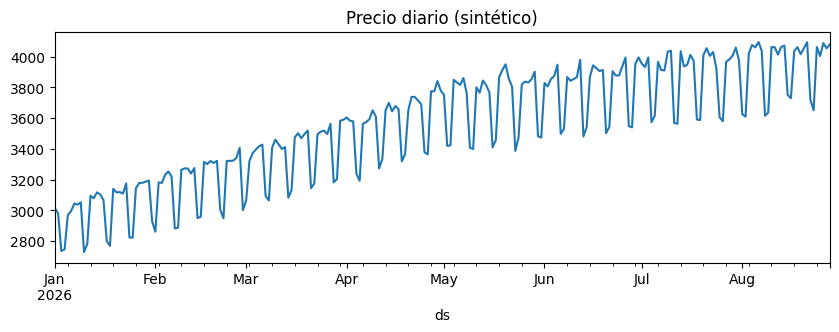

In [21]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
fechas = pd.date_range("2026-01-01", periods=240, freq="D")

precios, base = [], 3000.0
for i, f in enumerate(fechas):
    inflacion_mensual = 0.06 if i < 120 else 0.02
    base *= (1 + inflacion_mensual) ** (1 / 30)
    promo = 0.90 if f.dayofweek >= 5 else 1.0
    precios.append(base * promo * (1 + rng.normal(0, 0.01)))

historial = pd.DataFrame({"ds": fechas, "y": np.round(precios, 2)})   # Prophet exige columnas ds / y

H = 28
entrenamiento, prueba = historial.iloc[:-H], historial.iloc[-H:]

historial.set_index("ds")["y"].plot(figsize=(10, 3), title="Precio diario (sintético)");

### 4.a El test primero: un umbral de error

🦆 En pronósticos no existe "el valor exacto". El test mide el **error porcentual medio (MAPE)** en las 4 semanas que el modelo NO vio.
🦆 Contrato: **error menor al 2%**.

In [22]:
def mape(real, pronostico):
    real, pronostico = np.asarray(real), np.asarray(pronostico)
    return float(np.mean(np.abs((real - pronostico) / real)))

def test_pronostico_error_bajo(pronosticar):
    def test():
        error = mape(prueba["y"], pronosticar(entrenamiento, H))
        assert error < 0.02, f"MAPE {error:.1%} >= 2%"
    test.__name__ = f"test_error_bajo[{pronosticar.__name__}]"
    return test

### 4.b Reglas

🦆 **Regla 1, "último precio":** mañana sale lo mismo que hoy.
🦆 **Regla 2, "inflación histórica":** el último precio × la inflación mensual promedio del período.

In [23]:
def regla_ultimo_precio(train, h):
    return np.full(h, train["y"].iloc[-1])

def regla_inflacion(train, h):
    meses = (len(train) - 30) / 30
    infl = (train["y"].iloc[-30:].mean() / train["y"].iloc[:30].mean()) ** (1 / meses) - 1
    return train["y"].iloc[-1] * (1 + infl) ** (np.arange(1, h + 1) / 30)

correr_tests([test_pronostico_error_bajo(regla_ultimo_precio),
              test_pronostico_error_bajo(regla_inflacion)])

❌ ROJO   test_error_bajo[regla_ultimo_precio]  ->  MAPE 3.8% >= 2%
❌ ROJO   test_error_bajo[regla_inflacion]  ->  MAPE 3.7% >= 2%

0/2 tests en verde


### 4.c 🔍 ¿Dónde se rompió?

🦆 **Último precio:** ignora la tendencia y, si el último dato cae en fin de semana, arrastra la promo a todos los días.
🦆 **Inflación histórica:** promedia 6% y 2%, así que **sobreestima**: no se entera de que la inflación cambió.
🦆 Podríamos agregar "si es fin de semana restar 10%" y "usar solo el último mes"... y estaríamos construyendo a mano un modelo de series de tiempo, con números elegidos a ojo.

```
ROTURA DE GENERALIZACIÓN
  la serie tiene TENDENCIA QUE CAMBIA + ESTACIONALIDAD + RUIDO
  -> necesitamos un modelo que ESTIME esas componentes de los datos
```

### 4.d Prophet

Prophet descompone la serie en:

```
precio = tendencia (con puntos de cambio) × estacionalidad semanal × ruido
```

🦆 `changepoint_prior_scale`: cuánta libertad tiene la tendencia para cambiar de pendiente.
🦆 `seasonality_mode="multiplicative"`: la promo es un **porcentaje** del precio, no un monto fijo.
🦆 No es un LLM: es un **modelo estadístico** interpretable. Podemos graficar cada componente.

In [24]:
import logging
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)
from prophet import Prophet

def prophet_pronostico(train, h):
    m = Prophet(weekly_seasonality=True, yearly_seasonality=False, daily_seasonality=False,
                seasonality_mode="multiplicative", changepoint_prior_scale=0.5)
    m.fit(train)
    futuro = m.make_future_dataframe(periods=h)
    return m.predict(futuro)["yhat"].iloc[-h:].values

correr_tests([test_pronostico_error_bajo(regla_ultimo_precio),
              test_pronostico_error_bajo(regla_inflacion),
              test_pronostico_error_bajo(prophet_pronostico)])

❌ ROJO   test_error_bajo[regla_ultimo_precio]  ->  MAPE 3.8% >= 2%
❌ ROJO   test_error_bajo[regla_inflacion]  ->  MAPE 3.7% >= 2%
✅ VERDE  test_error_bajo[prophet_pronostico]

1/3 tests en verde


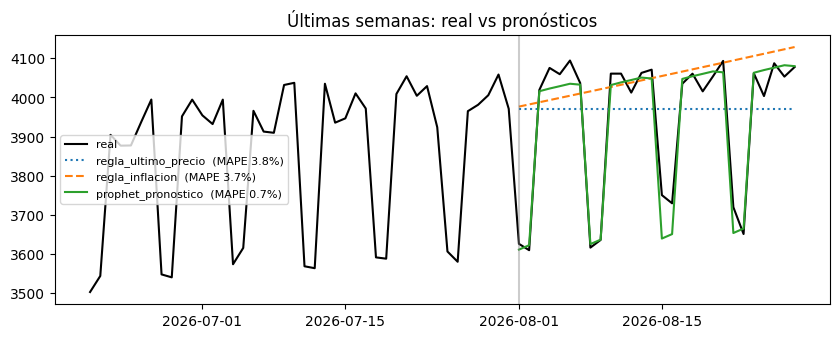

In [25]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(historial["ds"].iloc[-70:], historial["y"].iloc[-70:], color="black", label="real")
for f, estilo in [(regla_ultimo_precio, ":"), (regla_inflacion, "--"), (prophet_pronostico, "-")]:
    pred = f(entrenamiento, H)
    ax.plot(prueba["ds"], pred, estilo, label=f"{f.__name__}  (MAPE {mape(prueba['y'], pred):.1%})")
ax.axvline(prueba["ds"].iloc[0], color="gray", alpha=0.4)
ax.legend(fontsize=8); ax.set_title("Últimas semanas: real vs pronósticos");

> 👉 **Conclusión tramo 4: MODELO ESTADÍSTICO (Prophet).** No necesitamos un LLM para pronosticar números: un modelo de series de tiempo es más barato, más preciso y explicable.
>
> 💬 **Para discutir:** ¿qué pasa si hay una devaluación de un día para el otro? Ningún modelo la ve venir. Por eso un pronóstico siempre va con un **intervalo** (`yhat_lower`, `yhat_upper`), y conviene una regla de alerta: si el precio real se sale del intervalo, avisar a una persona.

---
# Tramo 5: MCP, el observatorio como herramienta

Hasta acá construimos funciones. ¿Cómo hacemos para que un asistente de IA (Claude, Gemini, un agente propio) las **use**?

🦆 **MCP (Model Context Protocol)** es un estándar para exponer herramientas a modelos de lenguaje.
🦆 El servidor MCP **no decide nada**: publica funciones con nombre, descripción y tipos. El agente elige cuál llamar.
🦆 Es la idea de toda la clase en grande: el LLM conversa y elige, y las herramientas deterministas (reglas y modelos testeados) hacen el trabajo.

```
usuario: "¿dónde está más barata la Coca?"
   │
   ▼
agente (LLM) ──elige herramienta──> servidor MCP
                                     ├─ comparar_precio()    -> rapidfuzz + catálogo (T1-T3)
                                     └─ pronosticar_precio() -> Prophet (T4)
```

### 5.a Tests primero

In [26]:
def test_mcp_lista_herramientas():
    nombres = sorted(t.name for t in correr(listar_herramientas()))
    esperar(nombres, ["comparar_precio", "pronosticar_precio"])

def test_mcp_comparar_coca():
    r = correr(llamar("comparar_precio", {"consulta": "coca original"}))
    esperar(r["mas_barato"], "B")

def test_mcp_comparar_typo():
    r = correr(llamar("comparar_precio", {"consulta": "yerva playadito"}))
    esperar(r["producto"], "Yerba Playadito 1 kg")

def test_mcp_pronostico_dias():
    r = correr(llamar("pronosticar_precio", {"dias": 7}))
    esperar(len(r["pronostico"]), 7)

def test_mcp_pronostico_limite():
    r = correr(llamar("pronosticar_precio", {"dias": 365}))
    assert "error" in r, "debería rechazar horizontes mayores a 60 días"

TESTS_MCP = [test_mcp_lista_herramientas, test_mcp_comparar_coca, test_mcp_comparar_typo,
             test_mcp_pronostico_dias, test_mcp_pronostico_limite]

### 5.b El servidor

🦆 `@mcp.tool` convierte una función en herramienta. El **docstring** es lo que lee el LLM para decidir cuándo usarla, así que hay que escribirlo bien.
🦆 Los **type hints** se convierten en el esquema de entrada.
🦆 `comparar_precio` usa `rapidfuzz.process.extractOne` para tolerar typos en la consulta (`yerva`).
🦆 `pronosticar_precio` tiene una **regla de guarda**: no pronostica más de 60 días.

In [27]:
from fastmcp import FastMCP, Client
from rapidfuzz import process

mcp = FastMCP("observatorio-precios")

# El modelo de Prophet se entrena una vez con todo el historial
modelo_precio = Prophet(weekly_seasonality=True, yearly_seasonality=False, daily_seasonality=False,
                        seasonality_mode="multiplicative", changepoint_prior_scale=0.5).fit(historial)


@mcp.tool
def comparar_precio(consulta: str) -> dict:
    '''Compara el precio de un producto entre la tienda A y la tienda B.
    Acepta nombres aproximados o con errores de tipeo (ej: "coca original", "yerva playadito").'''
    nombres = [normalizar(f["producto"]) for f in CATALOGO]
    _, score, idx = process.extractOne(normalizar(consulta), nombres, scorer=fuzz.WRatio)
    if score < 60:
        return {"error": f"No encontré '{consulta}' en el catálogo"}
    fila = CATALOGO[idx]
    if fila["precio_b"] is None:
        mas_barato = "solo A"
    else:
        mas_barato = "A" if fila["precio_a"] <= fila["precio_b"] else "B"
    return {**fila, "mas_barato": mas_barato, "score_busqueda": round(score)}


@mcp.tool
def pronosticar_precio(dias: int = 14) -> dict:
    '''Pronostica el precio diario del producto monitoreado para los próximos días (máximo 60).
    Devuelve el valor esperado y un intervalo de confianza del 80%.'''
    if not 1 <= dias <= 60:
        return {"error": "El horizonte tiene que estar entre 1 y 60 días"}
    futuro = modelo_precio.make_future_dataframe(periods=dias)
    fc = modelo_precio.predict(futuro).iloc[-dias:]
    return {"pronostico": [
        {"fecha": str(r.ds.date()), "esperado": round(r.yhat, 2),
         "minimo": round(r.yhat_lower, 2), "maximo": round(r.yhat_upper, 2)}
        for r in fc.itertuples()
    ]}

print("Servidor MCP listo:", mcp.name)

Servidor MCP listo: observatorio-precios


### 5.c Probarlo como lo haría un agente

🦆 `fastmcp.Client` se conecta al servidor **en memoria**, usando el protocolo MCP real (el mismo que usaría Claude Desktop), pero sin abrir puertos.
🦆 Los clientes MCP son **asíncronos**: por eso aparecen `async` / `await`.

In [28]:
import asyncio
from concurrent.futures import ThreadPoolExecutor

def correr(corrutina):
    # Jupyter ya tiene un event loop andando, así que corremos la corrutina en un hilo aparte
    with ThreadPoolExecutor(1) as ex:
        return ex.submit(asyncio.run, corrutina).result()

async def listar_herramientas():
    async with Client(mcp) as c:
        return await c.list_tools()

async def llamar(herramienta, argumentos):
    async with Client(mcp) as c:
        resultado = await c.call_tool(herramienta, argumentos)
        return resultado.data

correr_tests(TESTS_MCP)

✅ VERDE  test_mcp_lista_herramientas
✅ VERDE  test_mcp_comparar_coca
✅ VERDE  test_mcp_comparar_typo
✅ VERDE  test_mcp_pronostico_dias
✅ VERDE  test_mcp_pronostico_limite

5/5 tests en verde


In [29]:
for t in correr(listar_herramientas()):
    print(f"🔧 {t.name}\n   {t.description.strip().splitlines()[0]}\n")

print(correr(llamar("comparar_precio", {"consulta": "yerva playadito"})))
print()
for d in correr(llamar("pronosticar_precio", {"dias": 3}))["pronostico"]:
    print(d)

🔧 comparar_precio
   Compara el precio de un producto entre la tienda A y la tienda B.

🔧 pronosticar_precio
   Pronostica el precio diario del producto monitoreado para los próximos días (máximo 60).

{'producto': 'Yerba Playadito 1 kg', 'presentacion': 1000, 'precio_a': 4999.0, 'precio_b': 4850.0, 'nombre_b': 'YERBA MATE PLAYADITO 1 KG', 'mas_barato': 'B', 'score_busqueda': 93}

{'fecha': '2026-08-29', 'esperado': 3677.25, 'minimo': 3641.17, 'maximo': 3717.62}
{'fecha': '2026-08-30', 'esperado': 3683.71, 'minimo': 3641.75, 'maximo': 3722.72}
{'fecha': '2026-08-31', 'esperado': 4082.99, 'minimo': 4037.61, 'maximo': 4120.74}


### 5.d Usarlo fuera de Colab

En tu compu, guardá las funciones y el servidor en `servidor_precios.py` y terminá el archivo con:

```python
if __name__ == "__main__":
    mcp.run()          # stdio: el cliente lanza el proceso y se comunica por entrada/salida
```

Para conectarlo a Claude Desktop, agregalo a la configuración de servidores MCP:

```json
{
  "mcpServers": {
    "observatorio-precios": {
      "command": "python",
      "args": ["/ruta/a/servidor_precios.py"]
    }
  }
}
```

🦆 Gemini CLI y otros clientes usan un formato de configuración muy parecido.
🦆 Desde ese momento, el asistente puede responder "¿dónde conviene comprar la yerba?" llamando a **tus** herramientas testeadas.

> 👉 **Conclusión tramo 5: MCP es INTEGRACIÓN, no inteligencia.** Las garantías vienen de los tests de los tramos 1 a 4. MCP solo las pone al alcance del agente.

---
# El mapa final

| Tramo | Herramienta | Tipo | Por qué | Tipo de test |
|---|---|---|---|---|
| 1. Leer HTML | ~~re~~ → BeautifulSoup | regla estructural | el HTML es un árbol | caso exacto |
| 2. Precio y presentación | re | regla | formato cerrado, roturas de lógica | caso exacto |
| 3a. Match obvio | rapidfuzz | heurística | similitud de letras | accuracy en pares |
| 3b. Match dudoso | Gemini + LangChain | LLM | hace falta conocimiento del mundo | accuracy + guardrails |
| 4. Pronóstico | Prophet | modelo estadístico | tendencia + estacionalidad | umbral de MAPE |
| 5. Exponer | MCP (fastmcp) | integración | que un agente lo use | contrato de herramientas |

## Tres tipos de rotura

```
LÓGICA                    -> otra regla                     (pack vs N°7)
HERRAMIENTA EQUIVOCADA    -> otra regla, mejor herramienta  (re -> BeautifulSoup)
GENERALIZACIÓN            -> modelo                         (umbral de rapidfuzz, inflación que cambia)
```

## Checklist

🦆 ¿El formato es cerrado? -> `re`
🦆 ¿Tiene estructura (HTML, JSON, XML)? -> un parser, no un regex
🦆 ¿Son textos parecidos con ruido? -> `rapidfuzz` con umbrales
🦆 ¿Hay una zona gris que pide significado? -> LLM **solo ahí**, con salida estructurada y guardrails
🦆 ¿Son números en el tiempo? -> modelo de series (Prophet), no un LLM
🦆 ¿Lo va a usar un agente? -> MCP, con docstrings claros y reglas de guarda en cada herramienta

---
# 🏋️ Ejercicio

**Aparece una tienda C** que no tiene HTML: publica una API que devuelve JSON.

```python
TIENDA_C = [
    {"desc": "Gaseosa Coca Cola Original 2250cc", "precio_lista": 3600, "promo": 0.15},
    {"desc": "Galletitas Oreo Original x 118 Grs", "precio_lista": 1350, "promo": 0},
    {"desc": "Yerba Playadito Elaborada Con Palo 1Kg", "precio_lista": 5100, "promo": 0.10},
]
```

🦆 1. ¿Qué tramo hay que cambiar para leer la tienda C? ¿Hace falta BeautifulSoup?
🦆 2. Escribí tests para `presentacion("... 2250cc")` y `presentacion("... 1Kg")`. ¿Pasan sin tocar nada?
🦆 3. Calculá el precio final con la promo. ¿Regla o modelo?
🦆 4. Agregá 3 pares A-C a `PARES` con su etiqueta. ¿Cuántos caen en la zona gris?
🦆 5. Agregá a `CATALOGO` la columna `precio_c` y actualizá `comparar_precio` para que compare las 3 tiendas. Escribí el test primero.

In [30]:
TIENDA_C = [
    {"desc": "Gaseosa Coca Cola Original 2250cc", "precio_lista": 3600, "promo": 0.15},
    {"desc": "Galletitas Oreo Original x 118 Grs", "precio_lista": 1350, "promo": 0},
    {"desc": "Yerba Playadito Elaborada Con Palo 1Kg", "precio_lista": 5100, "promo": 0.10},
]

def test_presentacion_cc():
    esperar(presentacion("Gaseosa Coca Cola Original 2250cc"), 2250)

def test_presentacion_kg_pegado():
    esperar(presentacion("Yerba Playadito Elaborada Con Palo 1Kg"), 1000)

# TODO: tus tests

correr_tests([test_presentacion_cc, test_presentacion_kg_pegado])

✅ VERDE  test_presentacion_cc
✅ VERDE  test_presentacion_kg_pegado

2/2 tests en verde


### ✍️ Tu diagnóstico

🦆 Tramo que cambió: ...
🦆 Tipo de rotura: lógica / herramienta equivocada / generalización
🦆 Herramienta elegida y por qué: ...